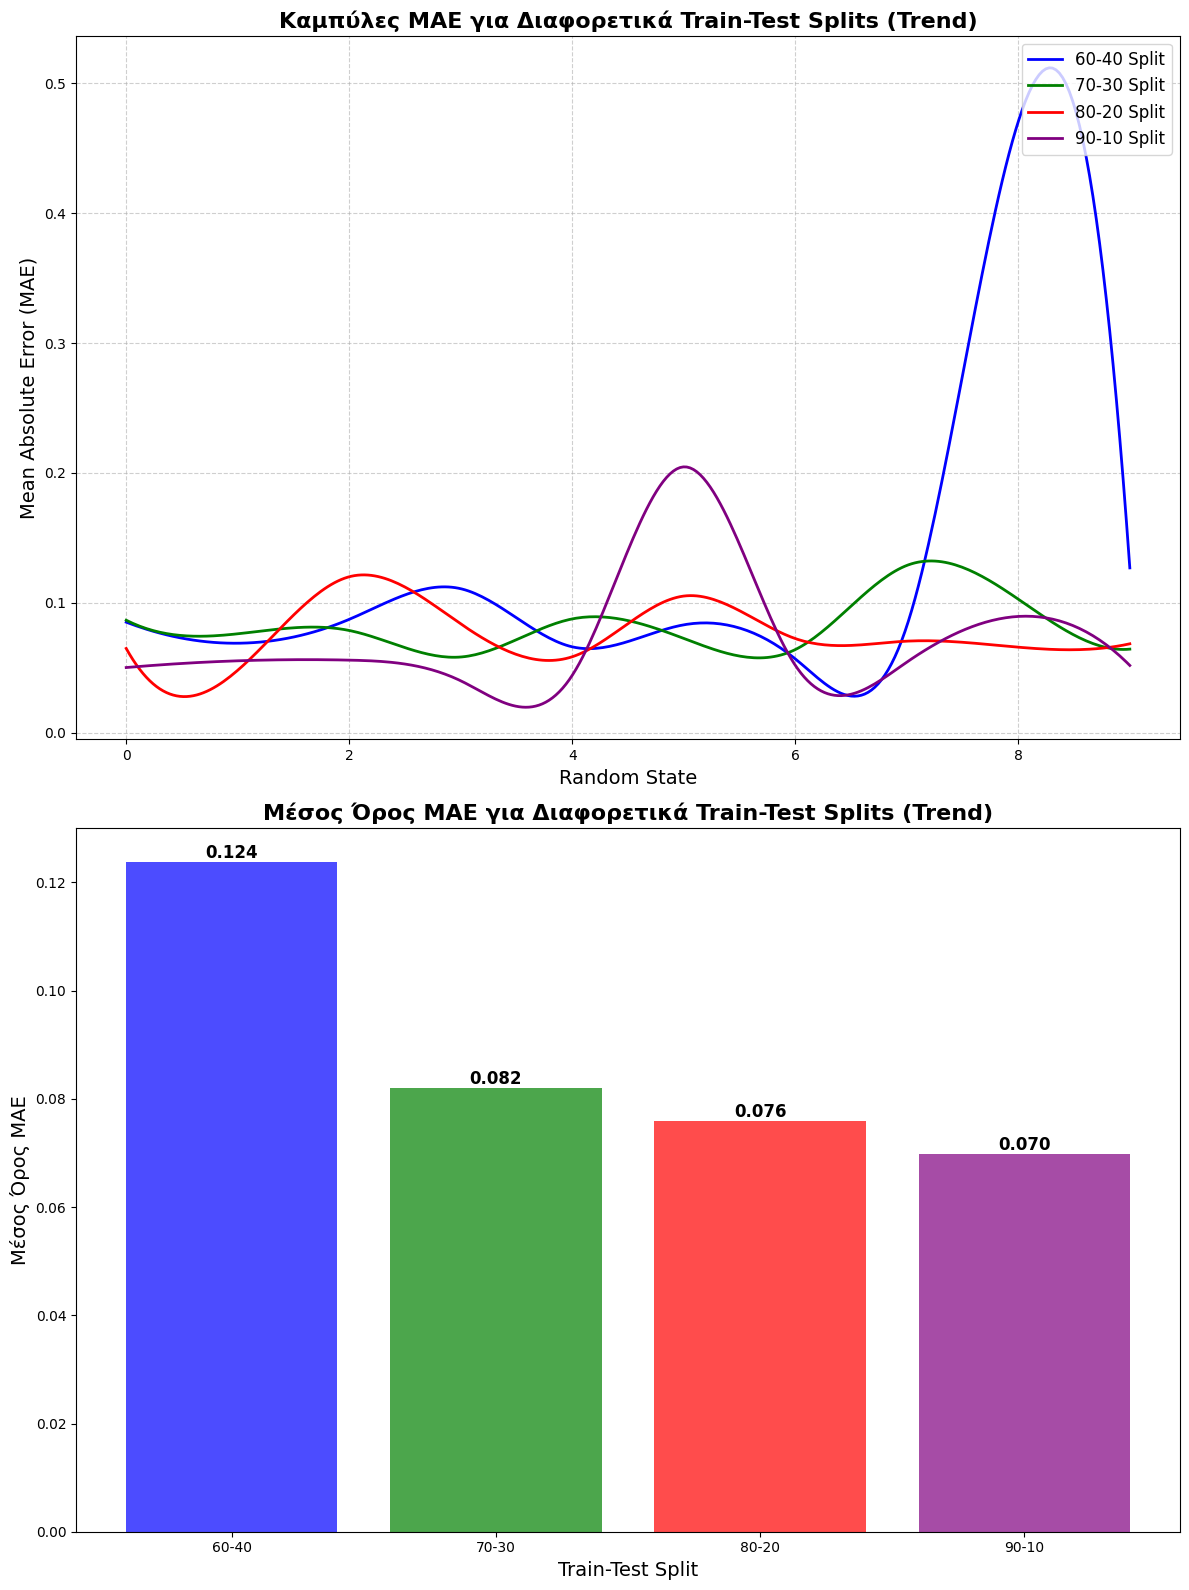

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.interpolate import make_interp_spline

# Δεδομένα για τα splits
random_states = np.array(list(range(10)))

mae_60_40 =np.array([
    0.08515054035605267, 0.06895080354658562, 0.0873296927700656,
    0.1108981350383177, 0.06616669834575438, 0.08311182420886143,
    0.05690670249882035, 0.08215746756483423, 0.47049671688899,
    0.12692858243583796
])
mae_70_30 = np.array([
    0.08665062087841102, 0.07620299119896694, 0.07875843929117923,
    0.058340805252309065, 0.0876701742731531, 0.07264590325068149,
    0.06406153818308041, 0.12880841050237096, 0.10284080803351967,
    0.06440275758723445
])
mae_80_20 = np.array([
    0.06492794212384868, 0.048138563563139815, 0.12009744598026763,
    0.08379961300029064, 0.058532040017120354, 0.1052436544205621,
    0.07251990587751035, 0.07054152425649708, 0.06589781959179408,
    0.0685092716846647
])
mae_90_10 = np.array([
    0.05023481852412193, 0.055416212841719936, 0.055942405819985164,
    0.040029067345409744, 0.04427302122267149, 0.20468196078242107,
    0.05196027774610005, 0.054373478243992086, 0.08957130420227861,
    0.05184424143533527
])

# Υπολογισμός μέσου όρου για κάθε split
mean_mae = [
    mae_60_40.mean(),
    mae_70_30.mean(),
    mae_80_20.mean(),
    mae_90_10.mean()
]

splits = ["60-40", "70-30", "80-20", "90-10"]

# Δημιουργία λείων καμπυλών με Spline Interpolation
x_smooth = np.linspace(random_states.min(), random_states.max(), 300)

mae_60_40_smooth = make_interp_spline(random_states, mae_60_40)(x_smooth)
mae_70_30_smooth = make_interp_spline(random_states, mae_70_30)(x_smooth)
mae_80_20_smooth = make_interp_spline(random_states, mae_80_20)(x_smooth)
mae_90_10_smooth = make_interp_spline(random_states, mae_90_10)(x_smooth)

# Δημιουργία γραφικής παράστασης
fig, axes = plt.subplots(2, 1, figsize=(12, 16))

# Πρώτο γράφημα: Καμπύλες MAE
axes[0].plot(x_smooth, mae_60_40_smooth, color='blue', label='60-40 Split', linewidth=2)
axes[0].plot(x_smooth, mae_70_30_smooth, color='green', label='70-30 Split', linewidth=2)
axes[0].plot(x_smooth, mae_80_20_smooth, color='red', label='80-20 Split', linewidth=2)
axes[0].plot(x_smooth, mae_90_10_smooth, color='purple', label='90-10 Split', linewidth=2)

axes[0].set_title('Καμπύλες MAE για Διαφορετικά Train-Test Splits (Trend)', fontsize=16, fontweight='bold')
axes[0].set_xlabel('Random State', fontsize=14)
axes[0].set_ylabel('Mean Absolute Error (MAE)', fontsize=14)
axes[0].grid(True, linestyle='--', alpha=0.6)
axes[0].legend(fontsize=12, loc='upper right')

# Δεύτερο γράφημα: Bar Chart Μέσων Όρων MAE
bars = axes[1].bar(splits, mean_mae, color=['blue', 'green', 'red', 'purple'], alpha=0.7)

axes[1].set_title('Μέσος Όρος MAE για Διαφορετικά Train-Test Splits (Trend)', fontsize=16, fontweight='bold')
axes[1].set_xlabel('Train-Test Split', fontsize=14)
axes[1].set_ylabel('Μέσος Όρος MAE', fontsize=14)

# Προσθήκη τιμών πάνω από τις μπάρες
for bar, value in zip(bars, mean_mae):
    axes[1].text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f'{value:.3f}',
        ha='center', va='bottom', fontsize=12, fontweight='bold'
    )

plt.tight_layout()
plt.show()
